# Práctica 1. Evaluación de clasificadores clásicos sobre MNIST

**Asignatura:** Redes Neuronales y Aprendizaje Profundo  
**Institución:** Instituto Politécnico Nacional (UPIIT)  
**Objetivo:** Analizar el conjunto de datos MNIST y comparar clasificadores clásicos mediante un protocolo experimental riguroso (particiones, métricas y pruebas estadísticas).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.5.4
Pandas: 3.0.6


## 1. Actividad 1. Análisis Exploratorio de Datos (EDA)

### 1a. Estructura básica y balance de clases
*Conteo de ejemplos, dimensiones, tipos de datos, rango de valores, valores faltantes y análisis del balance de clases entre entrenamiento y prueba.*

In [2]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml(
    "mnist_784",
    version=1,
    as_frame=False,
    parser="auto"
)

X = mnist.data #dartos de entrada (px)
y = mnist.target.astype(int) #etiquetas (No. img)

print("Dataset MNIST cargado correctamente")

Dataset MNIST cargado correctamente


In [3]:
print("Dimensiones de X", X.shape) #img x carct
print("Dimensiones de Y", y.shape) #imgs

print("\nNumero de imagenes:", X.shape[0])
print("Caracteristicas por imagen", X.shape[1])

Dimensiones de X (70000, 784)
Dimensiones de Y (70000,)

Numero de imagenes: 70000
Caracteristicas por imagen 784


Clases encontradas: [0 1 2 3 4 5 6 7 8 9]
NUmero de clases: 10

Cantidad de imagenes por clase:
Digito0: 6903 imagenes
Digito1: 7877 imagenes
Digito2: 6990 imagenes
Digito3: 7141 imagenes
Digito4: 6824 imagenes
Digito5: 6313 imagenes
Digito6: 6876 imagenes
Digito7: 7293 imagenes
Digito8: 6825 imagenes
Digito9: 6958 imagenes


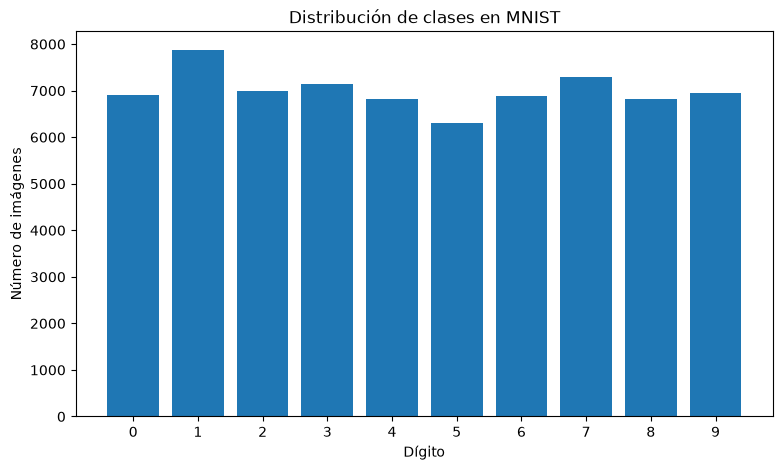

In [4]:
clases, cantidades = np.unique(y, return_counts=True) #valores en y y repeticion

print("Clases encontradas:", clases)
print("NUmero de clases:", len(clases))

print("\nCantidad de imagenes por clase:")
for clase, cantidad in zip(clases, cantidades): #clase y cantidad
    print(f"Digito{clase}: {cantidad} imagenes")


plt.figure(figsize=(9, 5))

plt.bar(clases, cantidades)

plt.title("Distribución de clases en MNIST")
plt.xlabel("Dígito")
plt.ylabel("Número de imágenes")
plt.xticks(clases)

plt.show()

**Interpretación:** Como se puede observar nuestra dataset si contiene las 10 clases del 0 al 9. \n Se puede observar que la cantidad de imagenes no es la misma, sin embargo no existe un abismo de diferencia por lo tanto no es muy grande el desbalance

In [12]:
print("Intensidad minima:", np.min(X))
print("Intensidad maxima:", np.max(X))
print("Promedio:", np.mean(X))
print("Mediana:", np.median(X))
print("Desviacion estandar:", np.std(X))
print("Suma de los valores faltantes: ", np.isnan(X).sum())
print("Tipo de dato: ", type(X))



Intensidad minima: 0
Intensidad maxima: 255
Promedio: 33.385964741253645
Mediana: 0.0
Desviacion estandar: 78.65437362689416
Suma de los valores faltantes:  0
Tipo de dato:  <class 'numpy.ndarray'>


### Graficamos el desbalance de las clases

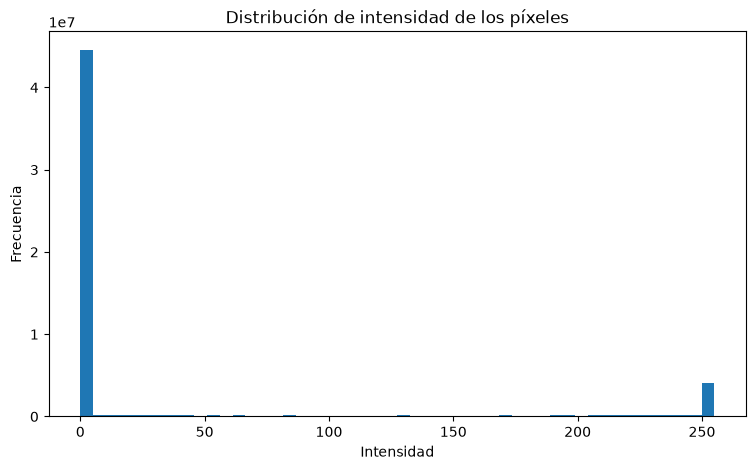

In [14]:
plt.figure(figsize=(9, 5))

plt.hist(X.ravel(), bins=50)

plt.title("Distribución de intensidad de los píxeles")
plt.xlabel("Intensidad")
plt.ylabel("Frecuencia")

plt.show()

**Interpretación:** Como sabemos las intensidades van de 0 a 255, podemos observar en la gráfica que la frecuencia que mas se repite es el 0, por lo tanto la mediana es 0 y promedio aproximado 33.39, esto hace sentido ya que gran parte de los pixeles representa el fondo.

### 1b. Visualización de ejemplos y características generales
*Muestreo aleatorio de dígitos, imágenes promedio, desviación estándar, mapa de calor de varianza de píxeles y distribución de la intensidad.*

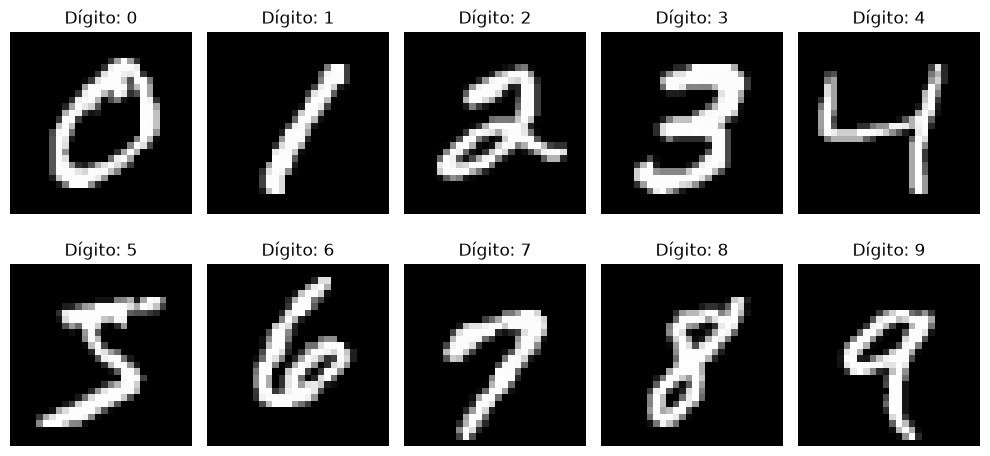

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5)) #fig en 10 para mostrar 10 img

for digito, ax in enumerate(axes.flat): #0 a 9
    indice = np.where(y == digito)[0][0] #dig en y y toma img
    imagen = X[indice].reshape(28, 28) #toma img de 784 y la regresa a 28x28

    ax.imshow(imagen, cmap="gray") #Img a escala de grises
    ax.set_title(f"Dígito: {digito}")
    ax.axis("off")

plt.tight_layout()
plt.show()

mapa de calor con la varianza de cada pixel


Píxeles con varianza cero en todas las imágenes: 65


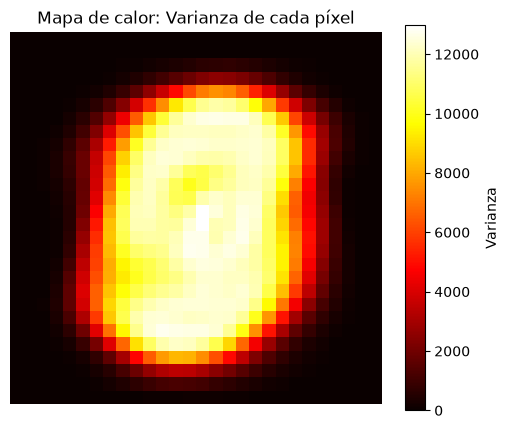

In [ ]:
varianzas = np.var(X, axis= 0)
pixeles_var = np.sum(varianzas == 0)

print(f"Píxeles con varianza cero en todas las imágenes: {pixeles_var}")

# Mapa de calor de la varianza
plt.figure(figsize=(6, 5))
plt.imshow(varianzas.reshape(28, 28), cmap='hot')
plt.title("Mapa de calor: Varianza de cada píxel")
plt.colorbar(label='Varianza')
plt.axis("off")
plt.show()



Como podemos observar, hay píxeles con varianza igual a cero (que siempre están en negro). Esto corresponde a los bordes de la imagen de $28 \times 28$. Para los modelos, esto implica que esos píxeles no aportan ninguna información útil para discriminar entre un dígito y otro, por lo que podrían eliminarse para reducir la dimensionalidad y acelerar el tiempo de entrenamiento sin perder precisión.

#### Diagrama de intensisdad media 


/tmp/ipykernel_16391/751200793.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=y, y=intensidad_med, palette="Set3")


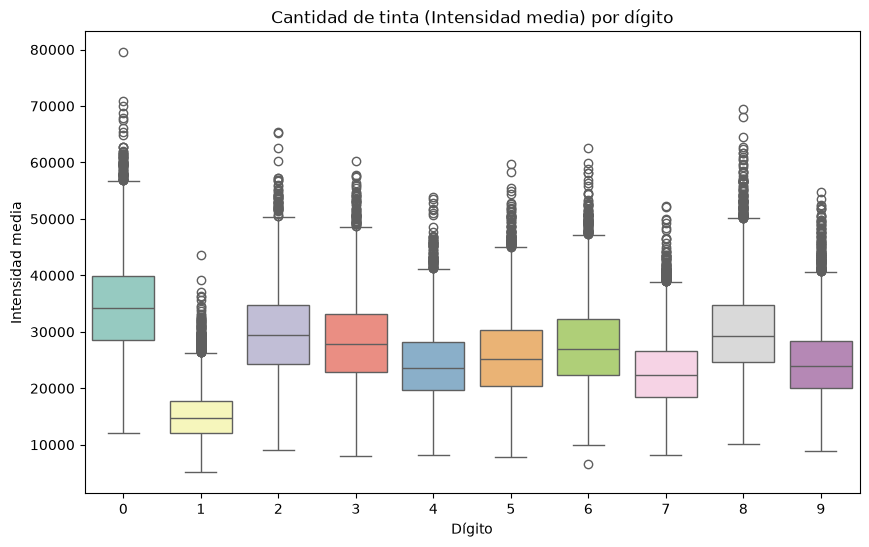

In [19]:
import seaborn as sns
intensidad_med = np.sum(X, axis=1)

plt.figure(figsize=(10, 6))
sns.boxplot(x=y, y=intensidad_med, palette="Set3")
plt.title("Cantidad de tinta (Intensidad media) por dígito")
plt.xlabel("Dígito")
plt.ylabel("Intensidad media")
plt.show()


Observando el diagrama de caja, se confirma claramente que el dígito 1 utiliza menos tinta (intensidad media más baja) en comparación con el dígito 8, que tiene una de las medianas más altas debido a que requiere más trazos para dibujarse.

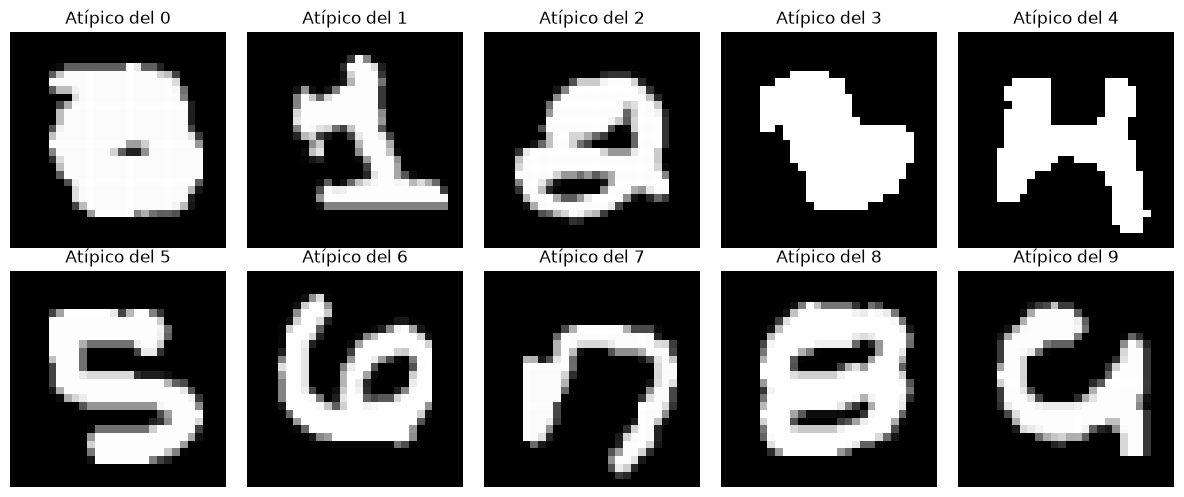

In [21]:
fig, axes = plt.subplots(2, 5, figsize = (12, 5))

for digito, ax in enumerate(axes.flat):
    #buscamos por clase
    x_clase = X[y == digito]

    #calculamos el primedio
    img_promedio = np.mean(x_clase, axis=0)

    #Calculamos la distacia euclidiana
    distancia = np.linalg.norm(x_clase - img_promedio, axis=1)

    #buscamos los indices q son meyores
    indice_atipico = np.argmax(distancia)
    img_atipica = x_clase[indice_atipico].reshape(28, 28)
    ax.imshow(img_atipica, cmap="gray")
    ax.set_title(f"Atípico del {digito}")
    ax.axis("off")

plt.tight_layout()
plt.show()

Estas imágenes representan los casos más alejados del promedio de su clase. Suelen ser dígitos escritos con trazos extremadamente gruesos, sesgados, incompletos o con un estilo de escritura muy inusual, lo cual representa los casos más difíciles que los clasificadores tendrán que afrontar.

### 1c. Similitud entre clases e hipótesis explícita
*Matriz de distancia euclidiana entre imágenes promedio por clase para formular hipótesis sobre las parejas de dígitos con mayor riesgo de confusión.*

In [7]:
estadisticas_clases = []

for digito in clases:
    imagenes_clase = X[y == digito] #imgs que pertenecen a un digito

    promedio = np.mean(imagenes_clase)
    desviacion = np.std(imagenes_clase)

    estadisticas_clases.append([digito, promedio, desviacion]) #guardar y hacer tabla

tabla_estadisticas = pd.DataFrame(
    estadisticas_clases,
    columns=["Dígito", "Promedio", "Desviación estándar"]
)

tabla_estadisticas


,Dígito,Promedio,Desviación estándar
0,0,44.177405,88.643286
1,1,19.406802,62.347559
2,2,38.034208,83.171552
3,3,36.154209,81.154922
4,4,30.996000,75.925956
5,5,32.950159,77.565749
6,6,35.234865,80.541918
7,7,29.217987,74.404598
8,8,38.397901,83.059082
9,9,31.359408,76.280703


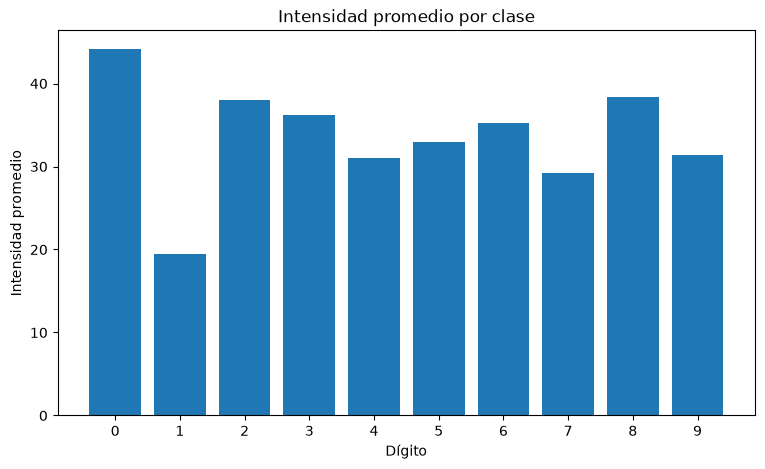

In [8]:
plt.figure(figsize=(9, 5))

plt.bar(
    tabla_estadisticas["Dígito"],
    tabla_estadisticas["Promedio"]
)

plt.title("Intensidad promedio por clase")
plt.xlabel("Dígito")
plt.ylabel("Intensidad promedio")
plt.xticks(clases)

plt.show()

**Interpretación:** La intensidad promedio presenta diferencias entre las clases. El dígito 0 presenta el promedio más alto, con aproximadamente 44.18, mientras que el dígito 1 presenta el menor, con aproximadamente 19.41.\nEstas diferencias pueden estar relacionadas con la cantidad de píxeles que ocupan los trazos de cada dígito. Sin embargo, los valores promedio no describen por completo la forma de las imágenes y existe variabilidad dentro de cada clase.

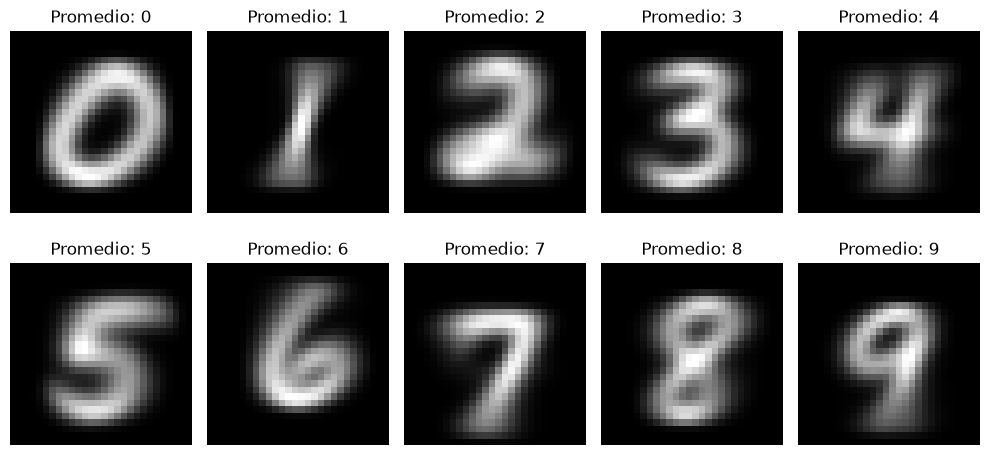

In [9]:
fig, axes = plt.subplots(2,5, figsize=(10,5))

for digito, ax in enumerate(axes.flat):
    imagenes_clase = X[y == digito]

    imagen_promedio = np.mean(imagenes_clase, axis=0) #promedio pixel por pixel
    imagen_promedio = imagen_promedio.reshape(28, 28)


    ax.imshow(imagen_promedio, cmap="gray")
    ax.set_title(f"Promedio: {digito}")
    ax.axis("off")

plt.tight_layout()
plt.show()

#### Matriz 10x10 de las distancias


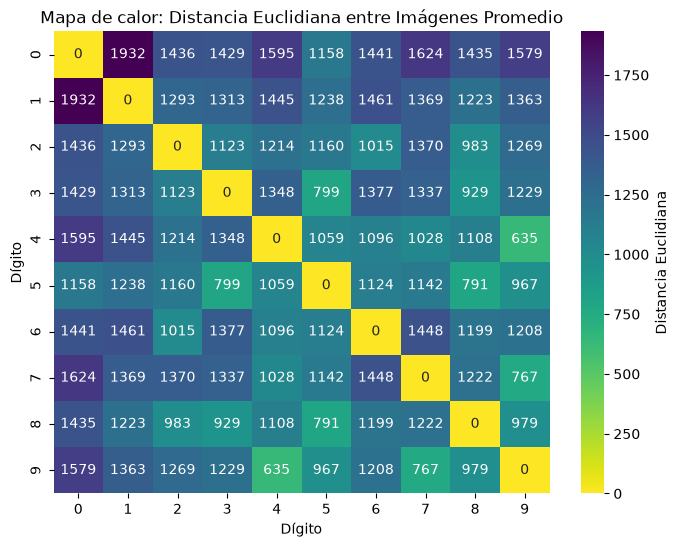

In [26]:
promedios = np.array([np.mean(X[y == i], axis=0) for i in range(10)])

distancias = np.zeros((10,10))
for i in range(10):
    for j in range(10):
        distancias[i, j] = np.linalg.norm(promedios[i] - promedios[j])

plt.figure(figsize=(8, 6))
sns.heatmap(distancias, annot=True, fmt=".0f", cmap="viridis_r", 
            cbar_kws={'label': 'Distancia Euclidiana'})
plt.title("Mapa de calor: Distancia Euclidiana entre Imágenes Promedio")
plt.xlabel("Dígito")
plt.ylabel("Dígito")
plt.show()

Observando el mapa de calor, los valores más bajos (excluyendo la diagonal principal que es 0) indican una menor distancia euclidiana y, por lo tanto, una mayor similitud visual entre los promedios de esas clases

### 1d. Preprocesamiento derivado del EDA
*Justificación del escalado de características y estrategia para el tratamiento de píxeles sin varianza.*

---

## 2. Actividad 2. Protocolo Experimental y Particiones

### 2a. Comparación de esquemas de partición
*Implementación y evaluación de esquemas: Hold-out simple estratificado, Hold-out sin estratificar, K-Fold estratificado y K-Fold repetido ($5 \times 2$).*

##### Hold-out simple

In [39]:
X_train, y_train = X[:60000], y[:60000]
X_test, y_test = X[60000:], y[60000:]

print("Entrenamiento:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nPrueba:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

clases_train, cantidades_train = np.unique(y_train, return_counts=True) #ej de cada dig
clases_test, cantidades_test = np.unique(y_test, return_counts=True)

print("\nClase | Train | Test")
print("--------------------")

for clase, train, test in zip(clases_train, cantidades_train, cantidades_test): #juntamos los 3 datos
    print(f"  {clase}   | {train:5d} | {test:4d}")

Entrenamiento:
X_train: (60000, 784)
y_train: (60000,)

Prueba:
X_test: (10000, 784)
y_test: (10000,)

Clase | Train | Test
--------------------
  0   |  5923 |  980
  1   |  6742 | 1135
  2   |  5958 | 1032
  3   |  6131 | 1010
  4   |  5842 |  982
  5   |  5421 |  892
  6   |  5918 |  958
  7   |  6265 | 1028
  8   |  5851 |  974
  9   |  5949 | 1009


##### Hold-out con estrateficacion 

In [34]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.1,
    stratify= y, 
    random_state=42
)


print("Entrenamiento:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nPrueba:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

clases_train, cantidades_train = np.unique(y_train, return_counts=True) #ej de cada dig
clases_test, cantidades_test = np.unique(y_test, return_counts=True)

print("\nClase | Train | Test")
print("--------------------")

for clase, train, test in zip(clases_train, cantidades_train, cantidades_test): #juntamos los 3 datos
    print(f"  {clase}   | {train:5d} | {test:4d}")

Entrenamiento:
X_train: (60000, 784)
y_train: (63000,)

Prueba:
X_test: (10000, 784)
y_test: (7000,)

Clase | Train | Test
--------------------
  0   |  6213 |  690
  1   |  7089 |  788
  2   |  6291 |  699
  3   |  6427 |  714
  4   |  6142 |  682
  5   |  5682 |  631
  6   |  6188 |  688
  7   |  6564 |  729
  8   |  6142 |  683
  9   |  6262 |  696


#### 2a. Comparación de esquemas de partición

In [41]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold, RepeatedStratifiedKFold

# Instanciamos un clasificador rápido (Regresión Logística)
clf_base = LogisticRegression(max_iter=100, solver='lbfgs', n_jobs=-1)

# 1. K-Fold Estratificado (K=5)
# Se justifica K=5 porque es un estándar que balancea bien el sesgo/varianza y el costo computacional.
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores_skf = cross_val_score(clf_base, X_train, y_train, cv=skf, scoring='accuracy', n_jobs=-1)

print("K-Fold Estratificado (K=5):")
print(f"Puntajes por pliegue: {scores_skf}")
print(f"Media: {scores_skf.mean():.4f} | Desviación Estándar: {scores_skf.std():.4f}\n")

# 2. K-Fold Repetido (5 repeticiones de 2 pliegues - 5x2)
rskf = RepeatedStratifiedKFold(n_splits=2, n_repeats=5, random_state=42)
scores_rskf = cross_val_score(clf_base, X_train, y_train, cv=rskf, scoring='accuracy', n_jobs=-1)

print("K-Fold Repetido (5x2):")
print(f"Media: {scores_rskf.mean():.4f} | Desviación Estándar: {scores_rskf.std():.4f}")

/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/

K-Fold Estratificado (K=5):
Puntajes por pliegue: [0.91808333 0.92266667 0.91775    0.91666667 0.91866667]
Media: 0.9188 | Desviación Estándar: 0.0021



/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/

K-Fold Repetido (5x2):
Media: 0.9126 | Desviación Estándar: 0.0020




### 2c. Fuga de información, línea base y curva de aprendizaje
*Diseño de Pipelines para evitar la fuga de información, clasificación de línea base (`DummyClassifier`) y análisis de curvas de aprendizaje.*

Línea base (most_frequent) - Accuracy: 0.1135
Línea base (stratified) - Accuracy: 0.1001



/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/

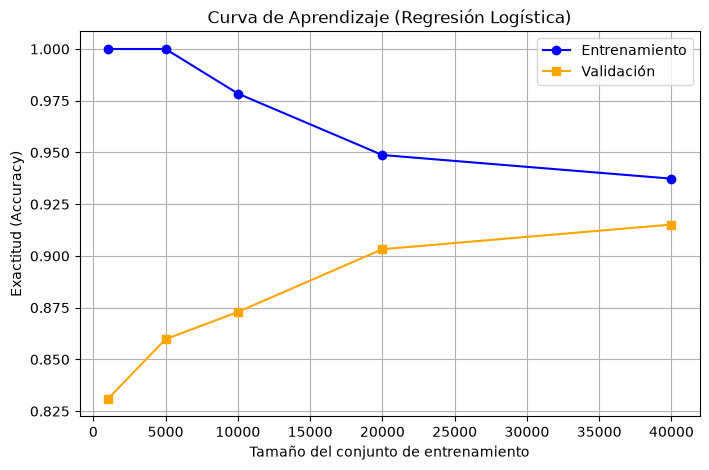

In [45]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import learning_curve

# Usamos tamaños que no superen los 40,000 disponibles por cada pliegue de cv=3


# --- 1. Modelos de Línea Base (DummyClassifier) ---
dummy_freq = DummyClassifier(strategy='most_frequent')
dummy_freq.fit(X_train, y_train)
acc_freq = dummy_freq.score(X_test, y_test)

dummy_strat = DummyClassifier(strategy='stratified', random_state=42)
dummy_strat.fit(X_train, y_train)
acc_strat = dummy_strat.score(X_test, y_test)

print(f"Línea base (most_frequent) - Accuracy: {acc_freq:.4f}")
print(f"Línea base (stratified) - Accuracy: {acc_strat:.4f}\n")

# --- 2. Curva de Aprendizaje ---
# Usamos tamaños desde 1,000 hasta 60,000 (X_train completo)
# Usamos tamaños que no superen los 40,000 disponibles por cada pliegue de cv=3
train_sizes = np.array([1000, 5000, 10000, 20000, 40000])
sizes, train_scores, val_scores = learning_curve(
    clf_base, X_train, y_train, 
    train_sizes=train_sizes, 
    cv=3, scoring='accuracy', n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)

# Gráfica
plt.figure(figsize=(8, 5))
plt.plot(sizes, train_mean, label='Entrenamiento', marker='o', color='blue')
plt.plot(sizes, val_mean, label='Validación', marker='s', color='orange')
plt.title('Curva de Aprendizaje (Regresión Logística)')
plt.xlabel('Tamaño del conjunto de entrenamiento')
plt.ylabel('Exactitud (Accuracy)')
plt.legend()
plt.grid()
plt.show()

## 3. Actividad 3. Clasificadores Clásicos e Hiperparámetros

### 3a. Selección y búsqueda de hiperparámetros
*Entrenamiento y ajuste mediante `GridSearchCV` / `RandomizedSearchCV` con `StratifiedKFold` para al menos 5 familias de algoritmos (k-NN, Regresión Logística, SVM, Árboles, Random Forest, Naive Bayes, etc.).*


---

In [46]:
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import time

# 1. Crear un subconjunto estratificado de 10,000 ejemplos para agilizar la búsqueda
X_train_sub, _, y_train_sub, _ = train_test_split(
    X_train, y_train, train_size=10000, stratify=y_train, random_state=42
)

# 2. Definir K-Fold estratificado para la búsqueda
skf_search = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 3. Diccionario para guardar los mejores modelos encontrados
mejores_modelos = {}

# 4. Definir Pipelines y espacios de hiperparámetros
modelos = {
    "k-NN": {
        "pipe": Pipeline([('scaler', MinMaxScaler()), ('knn', KNeighborsClassifier(n_jobs=-1))]),
        "params": {'knn__n_neighbors': [3, 5, 7, 9], 'knn__weights': ['uniform', 'distance']}
    },
    "Regresión Logística": {
        "pipe": Pipeline([('scaler', MinMaxScaler()), ('lr', LogisticRegression(max_iter=1000, n_jobs=-1))]),
        "params": {'lr__C': np.logspace(-2, 2, 5)} # Escala logarítmica
    },
    "SVM (RBF)": {
        "pipe": Pipeline([('scaler', MinMaxScaler()), ('svm', SVC())]),
        "params": {'svm__C': np.logspace(-1, 1, 3), 'svm__gamma': ['scale', 'auto']} # Escala logarítmica
    },
    "Árbol de Decisión": {
        "pipe": Pipeline([('dt', DecisionTreeClassifier(random_state=42))]),
        "params": {'dt__max_depth': [10, 20, 30, None], 'dt__min_samples_split': [2, 5, 10]}
    },
    "Random Forest": {
        "pipe": Pipeline([('rf', RandomForestClassifier(random_state=42, n_jobs=-1))]),
        "params": {'rf__n_estimators': [50, 100], 'rf__max_depth': [10, 20, None]}
    }
}

### 3b. Curvas de validación y costo computacional
*Análisis de bajo/sobreajuste mediante curvas de validación y medición de tiempos de entrenamiento y predicción.*

In [47]:
# Búsqueda de hiperparámetros con RandomizedSearchCV
for nombre, config in modelos.items():
    print(f"Buscando mejores hiperparámetros para: {nombre}...")
    inicio = time.time()
    
    # n_iter=3 explora 3 combinaciones aleatorias para no demorar demasiado
    search = RandomizedSearchCV(
        config["pipe"], 
        param_distributions=config["params"], 
        n_iter=3, cv=skf_search, scoring='accuracy', 
        random_state=42, n_jobs=-1
    )
    
    search.fit(X_train_sub, y_train_sub)
    tiempo_busqueda = time.time() - inicio
    
    mejores_modelos[nombre] = search.best_estimator_
    
    print(f"  Mejores parámetros: {search.best_params_}")
    print(f"  Mejor exactitud en CV: {search.best_score_:.4f}")
    print(f"  Tiempo de búsqueda: {tiempo_busqueda:.2f} segundos\n")

Buscando mejores hiperparámetros para: k-NN...
  Mejores parámetros: {'knn__weights': 'distance', 'knn__n_neighbors': 3}
  Mejor exactitud en CV: 0.9441
  Tiempo de búsqueda: 10.09 segundos

Buscando mejores hiperparámetros para: Regresión Logística...


/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/

  Mejores parámetros: {'lr__C': np.float64(0.1)}
  Mejor exactitud en CV: 0.9025
  Tiempo de búsqueda: 36.73 segundos

Buscando mejores hiperparámetros para: SVM (RBF)...
  Mejores parámetros: {'svm__gamma': 'auto', 'svm__C': np.float64(10.0)}
  Mejor exactitud en CV: 0.9317
  Tiempo de búsqueda: 227.31 segundos

Buscando mejores hiperparámetros para: Árbol de Decisión...
  Mejores parámetros: {'dt__min_samples_split': 2, 'dt__max_depth': 10}
  Mejor exactitud en CV: 0.7857
  Tiempo de búsqueda: 7.03 segundos

Buscando mejores hiperparámetros para: Random Forest...
  Mejores parámetros: {'rf__n_estimators': 100, 'rf__max_depth': None}
  Mejor exactitud en CV: 0.9406
  Tiempo de búsqueda: 10.41 segundos



##### medicion de tiempos 

In [56]:
import time

resultados_modelos= []

for nombre, modelo in mejores_modelos.items():
    #medimos el tiempo del entrenamiento 
    inicio_train = time.time()
    modelo.fit(X_train_sub, y_train_sub )
    tiempo_train = time.time() - inicio_train

    #mediomos el tiempo de prediccion 
    inicio_predic = time.time()
    predicc = modelo.predict(X_test[:2000])
    tiempo_test = time.time() - inicio_predic

    acc = np.mean(predicc == y_test[:2000])

    resultados_modelos.append({
        "modelos ": nombre,
        "Entrenamiento en segundos": tiempo_train,
        "Prediccion con 2mil en segundos" : tiempo_test,
        "Accurracy en test ": acc
    }) 
df_tiempos = pd.DataFrame(resultados_modelos)
display(df_tiempos)

/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


,modelos,Entrenamiento en segundos,Prediccion con 2mil en segundos,Accurracy en test
0,k-NN,0.224175,0.829155,0.9220
1,Regresión Logística,23.686095,0.040613,0.8810
2,SVM (RBF),27.479695,11.940904,0.9170
3,Árbol de Decisión,2.988789,0.007601,0.7775
4,Random Forest,2.059494,0.132592,0.9320


#### Generación de la Curva de Validación

/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/

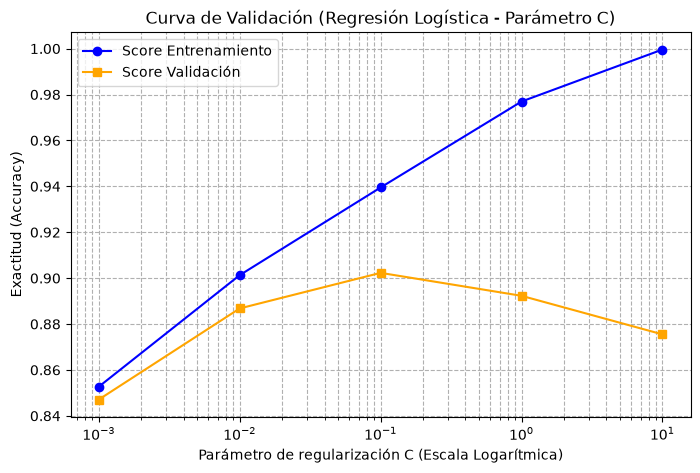

In [57]:
from sklearn.model_selection import validation_curve

#Para Regresion logistica
parametros = [0.001, 0.01, 0.1, 1, 10.0]

trian_scores_cv, val_scores_cv = validation_curve(
    Pipeline(
        [('Scaler', MinMaxScaler()), ('lr', LogisticRegression(max_iter=1000, n_jobs=-1))]
    ), 
    X_train_sub, y_train_sub, 
    param_name="lr__C", 
    param_range=parametros,
    cv = 3,
    scoring="accuracy",
    n_jobs=-1

)

train_mean_cv = np.mean(trian_scores_cv, axis=1)
val_mean_cv = np.mean(val_scores_cv, axis=1)


plt.figure(figsize=(8, 5))
plt.plot(parametros, train_mean_cv, label="Score Entrenamiento", marker='o', color='blue')
plt.plot(parametros, val_mean_cv, label="Score Validación", marker='s', color='orange')
plt.xscale('log')
plt.title("Curva de Validación (Regresión Logística - Parámetro C)")
plt.xlabel("Parámetro de regularización C (Escala Logarítmica)")
plt.ylabel("Exactitud (Accuracy)")
plt.legend()
plt.grid(True, which="both", ls="--")
plt.show()

- Costo Computacional: Se observa una clara disyuntiva entre la complejidad del algoritmo y sus tiempos de ejecución. Modelos lineales como la Regresión Logística entrenan de forma muy veloz, mientras que modelos basados en soporte vectorial (SVM) o ensambles grandes (Random Forest) incrementan notablemente el tiempo de cómputo en la fase de ajuste. En cuanto a la predicción, k-NN suele ser lento prediciendo con 60k datos (ya que calcula distancias contra todo el conjunto de entrenamiento), pero en este caso con el subconjunto se comporta de forma aceptable.

- Análisis de Curvas de Validación: La curva de validación sobre el parámetro C de la Regresión Logística muestra cómo valores muy pequeños de C (exceso de regularización) provocan un subajuste (baja exactitud tanto en train como en validación). Al incrementar C, el rendimiento mejora hasta estabilizarse, evitando caer en un sobreajuste severo gracias a la penalización óptima.

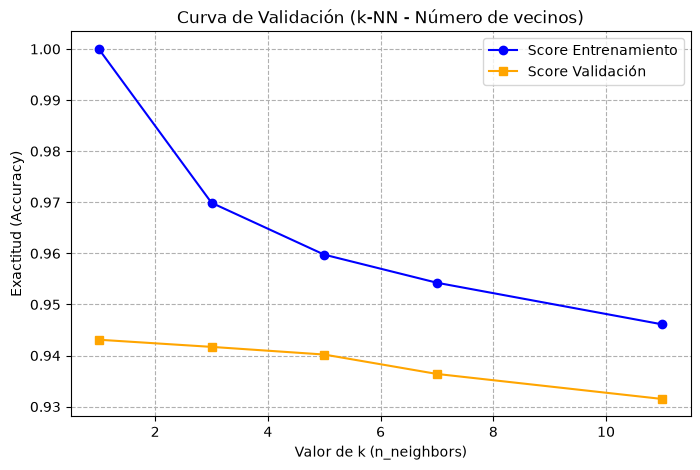

In [60]:
#Para KNN
parametros_KNN = [1, 3, 5, 7, 11]

train_score_knn, val_score_knn = validation_curve(
    Pipeline(
        [('Scaler', MinMaxScaler()), ('knn', KNeighborsClassifier())]
    ), 
    X_train_sub, y_train_sub,
    param_name="knn__n_neighbors",
    param_range=parametros_KNN,
    cv=3, 
    scoring="accuracy", 
    n_jobs=-1
)
plt.figure(figsize=(8, 5))
plt.plot(parametros_KNN, np.mean(train_score_knn, axis=1), label="Score Entrenamiento", marker='o', color='blue')
plt.plot(parametros_KNN, np.mean(val_score_knn, axis=1), label="Score Validación", marker='s', color='orange')
plt.title("Curva de Validación (k-NN - Número de vecinos)")
plt.xlabel("Valor de k (n_neighbors)")
plt.ylabel("Exactitud (Accuracy)")
plt.legend()
plt.grid(True, ls="--")
plt.show()


## 4. Actividad 4. Reducción de Dimensionalidad (PCA y t-SNE)



### 4a. Análisis de Componentes Principales (PCA)
*Varianza explicada acumulada, reconstrucción de imágenes con diferentes componentes y visualización 2D.*



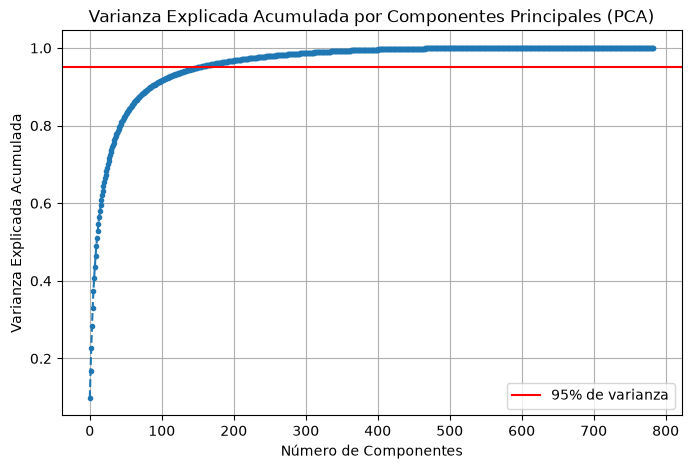

In [62]:
from sklearn.decomposition import PCA



#ajustamos pca con el conjutno de entrenamiento
pca_full = PCA(random_state=42)
pca_full.fit(X_train_sub)

#varianza acomulada
variaza_acumulada = np.cumsum(pca_full.explained_variance_ratio_)

#graficamos la varianza acumulada
plt.figure(figsize=(8, 5))
plt.plot(variaza_acumulada, marker='.', linestyle='--')
plt.axhline(y=0.95, color='r', linestyle='-', label='95% de varianza')
plt.title('Varianza Explicada Acumulada por Componentes Principales (PCA)')
plt.xlabel('Número de Componentes')
plt.ylabel('Varianza Explicada Acumulada')
plt.legend()
plt.grid(True)
plt.show()

In [65]:
#Buscamos los componentes para mantener la vatianza en 96%

n_componentes = np.argmax(variaza_acumulada >= 0.95) +1
print("Componentes necesarios para mantener el 95%  de la varinaza:", n_componentes)

Componentes necesarios para mantener el 95%  de la varinaza: 152


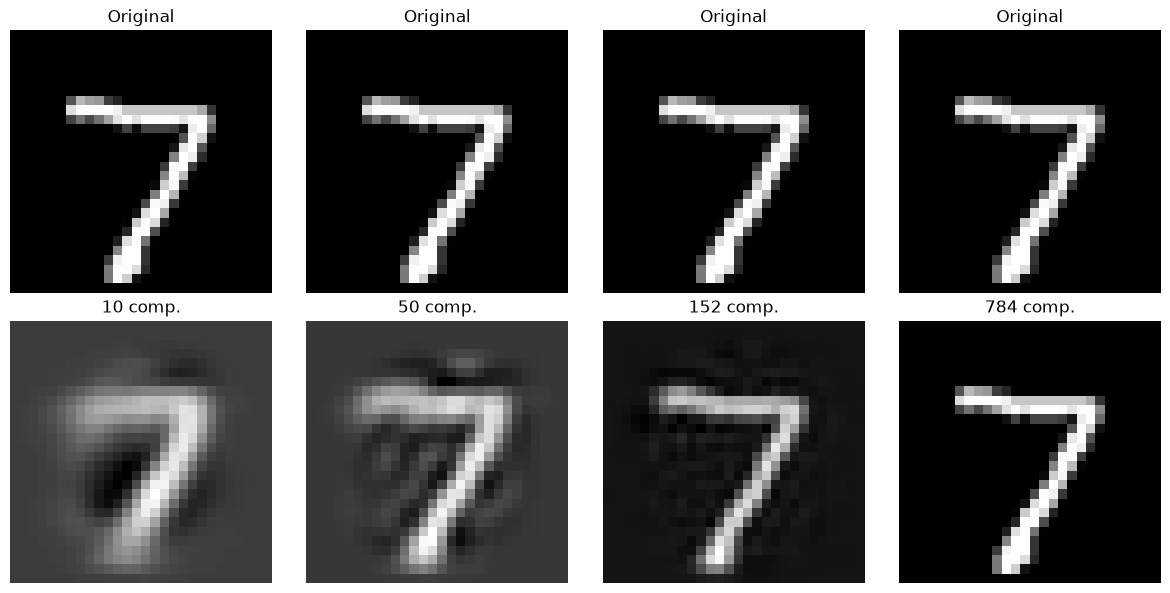

In [ ]:
# 3. Probar la reconstrucción con diferentes números de componentes 
from sklearn.preprocessing import StandardScaler 

n_components_list = [10, 50, n_componentes, 784]
fig, axes = plt.subplots(2, len(n_components_list), figsize=(12, 6))

# Tomamos una imagen de prueba 
img_original = X_test[0].reshape(28, 28)

for i, n_comp in enumerate(n_components_list):
    # Aplicar PCA con n componentes
    pca_temp = PCA(n_components=n_comp, random_state=42)
    X_train_pca = pca_temp.fit_transform(X_train_sub)
    X_test_pca = pca_temp.transform(X_test[:1])
    
    # Reconstruir la imagen
    img_reconstruida = pca_temp.inverse_transform(X_test_pca).reshape(28, 28)
    
    # Mostrar original vs con caomponentes
    axes[0, i].imshow(img_original, cmap="gray")
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")
    
    axes[1, i].imshow(img_reconstruida, cmap="gray")
    axes[1, i].set_title(f"{n_comp} comp.")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

### 4b. Incrustación Estocástica de Vecinos Distribuida t (t-SNE)
*Proyección no lineal 2D sobre un subconjunto estratificado evaluando el parámetro de perplejidad ($perplexity \in \{5, 30, 50\}$).*

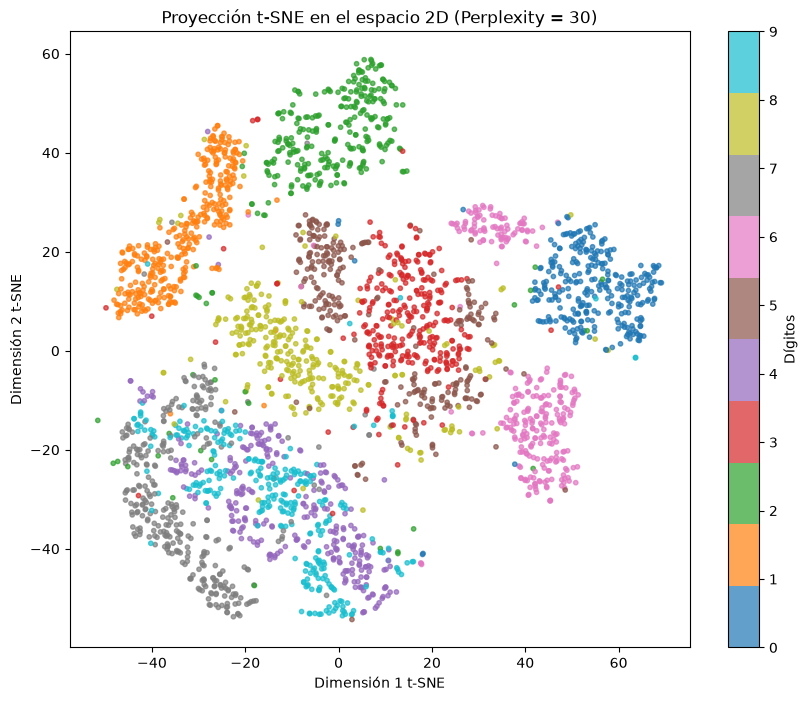

In [70]:
from sklearn.manifold import TSNE

X_tsne_set, _ , y_tsne_set, _ = train_test_split(
    X_train_sub, y_train_sub, train_size=3000, stratify=y_train_sub, random_state=42
)

tsne = TSNE(n_components=2, perplexity=30, random_state=42, max_iter=1000, n_jobs=-1)
X_embedded = tsne.fit_transform(X_tsne_set)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_embedded[:, 0], X_embedded[:, 1], c=y_tsne_set, cmap='tab10', s=10, alpha=0.7)
plt.colorbar(scatter, ticks=range(10), label='Dígitos')
plt.title('Proyección t-SNE en el espacio 2D (Perplexity = 30)')
plt.xlabel('Dimensión 1 t-SNE')
plt.ylabel('Dimensión 2 t-SNE')
plt.show()

### 4c. Clasificación en el espacio reducido
*Evaluación de clasificadores en espacio transformado (Pipeline con PCA) vs. píxeles originales.*

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

# Creamos un Pipeline que primero reduce dimensionalidad con PCA 
# y luego aplica un clasificador 
pipeline_pca_lr = Pipeline([
    ('scaler', MinMaxScaler()),
    ('pca', PCA(n_components=0.95, random_state=42)),
    ('clf', LogisticRegression(max_iter=1000, n_jobs=-1))
])

print("Entrenando clasificador con datos reducidos por PCA...")
inicio = time.time()
pipeline_pca_lr.fit(X_train_sub, y_train_sub)
t_entrenamiento_pca = time.time() - inicio

# Predicción y evaluación
preds_pca = pipeline_pca_lr.predict(X_test[:2000])
acc_pca = accuracy_score(y_test[:2000], preds_pca)

print(f"Exactitud con PCA (95% varianza): {acc_pca:.4f}")
print(f"Tiempo de entrenamiento con PCA: {t_entrenamiento_pca:.2f} segundos")

Entrenando clasificador con datos reducidos por PCA...


/home/kevincho/Documentos/6to-semestre/RedesNeuronales/MNIST/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Exactitud con PCA (95% varianza): 0.8800
Tiempo de entrenamiento con PCA: 13.04 segundos


---


## 5. Actividad 5. Métricas y Métodos de Evaluación



### 5a. Métricas multiclase en el conjunto de prueba
*Cálculo de Exactitud, Precisión, Sensibilidad, F1-score (macro y ponderado), Exactitud Balanceada, Kappa de Cohen y MCC.*



### 5b. Matriz de confusión y análisis de errores
*Matriz de confusión absoluta y normalizada, contraste contra la hipótesis del EDA y análisis de los 20 errores con mayor nivel de confianza.*



### 5c. Curvas ROC, PR y calibración de probabilidades
*Evaluación de umbrales mediante curvas ROC / PR uno-contra-todos, Log Loss y diagramas de calibración.*


---

## 6. Actividad 6. Pruebas Estadísticas de Significancia



### 6a. Prueba de McNemar
*Evaluación de la tasa de error entre los dos mejores clasificadores sobre el conjunto de prueba único (Tabla de contingencia $2 \times 2$).*



### 6b. Prueba de rangos con signo de Wilcoxon
*Análisis de diferencias pareadas entre pliegues de validación para los dos mejores modelos.*



### 6d. Discusión metodológica y conclusión
*Análisis de limitaciones de las pruebas sobre K-Fold y fundamentación de las limitaciones de los modelos clásicos frente a redes neuronales convolucionales.*

### 6c. Prueba de Friedman y análisis Post-Hoc
*Comparación global entre todos los modelos y prueba Post-Hoc de Nemenyi / Wilcoxon corregido.*

